- Source - https://www.linkedin.com/pulse/statistical-arbitrage-pairs-trading-backtesting-sabir-jana/
- This is buy and hold strategy
- here, if z score(ratio) goes below -1 : long signal (long stock 2 and short stock 1), hold it as long as it remains below -1 and once it goes above -1, liquidate your position
- here, if z score(ratio) goes above 1 : short signal(long stock 1 and short stock 2), hold it as long as it remains above 1 and once it goes below 1, liquidate your position


### Import Libraries : Exhaustive list, not all being used

In [ ]:
from PIL import Image

import os
dir_path = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs"

In [7]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

#-------------------------------------------------------------------------------------------------------------
# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

#-------------------------------------------------------------------------------------------------------------
# Self organizing maps(SOM)
from minisom import MiniSom

#-------------------------------------------------------------------------------------------------------------
# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

#-------------------------------------------------------------------------------------------------------------
# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

#-------------------------------------------------------------------------------------------------------------
# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco

# statsmodels is a Python package that provides a complement to scipy for statistical computations
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#-------------------------------------------------------------------------------------------------------------
# Shapley values, used in DTEM
import shap

# to reload another python script 
from importlib import reload

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# Trading Strategy backtesting
import ffn

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

# Pair Trading based on Cointegration and Backtesting

- Part 1: Creating a model that test for stationarity.
- Part 2: Creating a model that test for cointegration.
- Part 3: Assigning a portfolio of assests and testing for a cointegrated pair among the dataset.
- Part 4: Establishing features and labels that will allow us to create trading signals for the strategy

**We take the daily closing price for these 15 stocks and split the dataframe into test and training sets. This is to ensure that our decision to select a cointegrated pair is based on the training dataset and backtesting is done using out of sample test dataset.**

### Find Coinegrated pairs

In [8]:
def find_cointegrated_pairs(data):
    n = data.shape[1]
    coint_score_matrix = np.zeros(shape = (n,n))
    p_value_matrix = np.zeros(shape = (n,n))
    pairs = []
    stocks = data.columns
    
    for i in range(n):
        for j in range(i+1, n):
            s1 = data[stocks[i]]
            s2 = data[stocks[j]]
            result = coint(s1,s2)                           # coint()
            score = result[0]                               # results[0]
            p_value = result[1]
            coint_score_matrix[i,j] = score
            p_value_matrix[i,j] = p_value
            
            if p_value < 0.05:
                pairs.append((stocks[i],stocks[j]))
                
    return coint_score_matrix, p_value_matrix, pairs

In [9]:
tickers = ['AAPL', 'ADBE', 'ORCL', 'EBAY', 'MSFT', 'QCOM', 'HPQ', 'JNPR', 'AMD', 'IBM', 'SPY']
df = yf.download(tickers = tickers, start='2013-01-01', end='2018-01-01',progress =False)
df = df['Close']

train_price, test_price = train_test_split(df, test_size=0.5, shuffle=False)

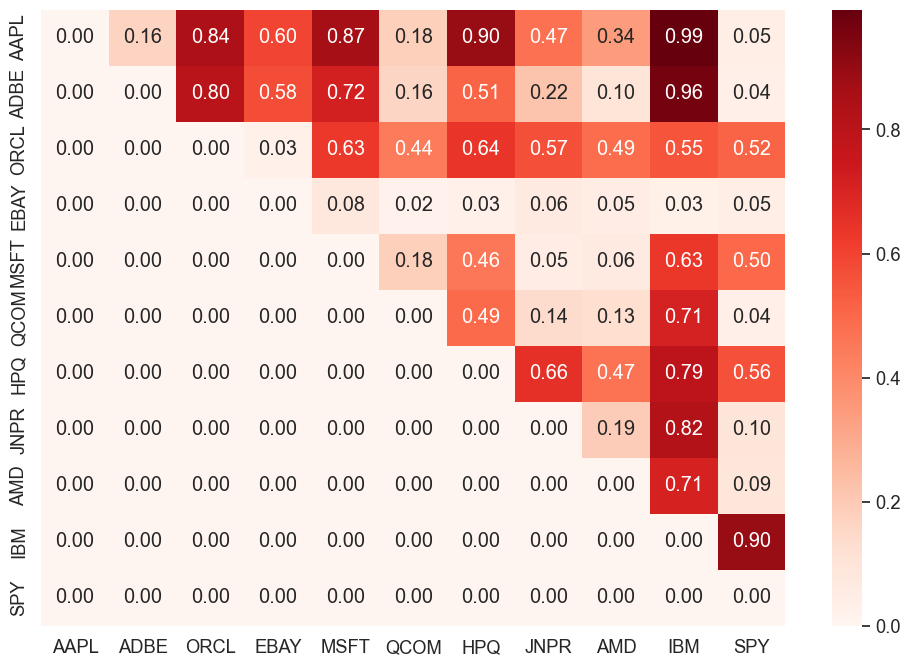

In [10]:
coint_score, pvalue, pairs = find_cointegrated_pairs(train_price)

plt.figure(figsize =(12,8))
sns.set(font_scale =1.2)
sns.heatmap(pvalue,annot= True,cmap = 'Reds', fmt ='0.2f',cbar = True,xticklabels=tickers, yticklabels=tickers)               
plt.show()

### Calculating the Spread

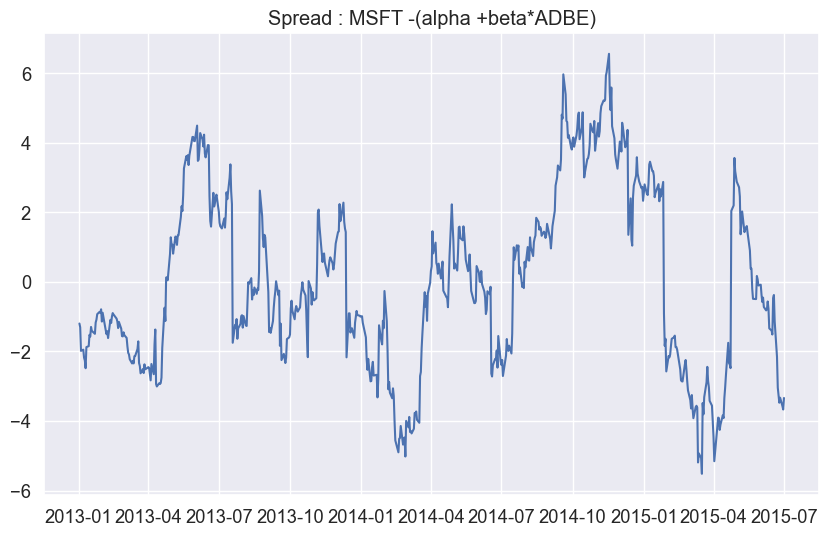

In [11]:
# We will first calculate the hedge ratio between these two tickers using OLS regression. 
# Then, using the hedge ratio, we will calculate the spread and run the Augmented Dickey-Fuller test. 

train_price = train_price.loc[:,['ADBE','MSFT']]
asset_1 = 'ADBE'
asset_2 = 'MSFT'


X = sm.add_constant(train_price['ADBE'])
y = train_price['MSFT']

model = sm.OLS(endog= y,exog = X)           # sm.OLS() - initialize the model,exogenous variable - Y, endogenious variable - X
results = model.fit()                       # model.fit()

# get parameters
results.params                              # results.params
alpha = results.params[0]

# hedge ratio
beta = results.params[1]                    

# spread 
spread = y - (alpha + beta* X['ADBE'])
plt.plot(spread)
plt.title('Spread : MSFT -(alpha +beta*ADBE)')
plt.show()

### To test cointegration is to implement the Dickey-Fuller test:

In [12]:
adf_test = adfuller(x = spread, maxlag =1)                                          # adfuller() with maxlag
index = ['test statistics','p-value','# of lagged values','# of observations']
adf_output = pd.Series(adf_test[0:4],index = index)

critical_values = pd.Series(adf_test[4],index = adf_test[4].keys())
print(adf_output)
print(critical_values)

test statistics       -2.8768
p-value                0.0481
# of lagged values     0.0000
# of observations    628.0000
dtype: float64
1%    -3.4408
5%    -2.8662
10%   -2.5692
dtype: float64


### Generate Trading Signals using z-score of Ratio

**We have used the training dataset until this point to finalize the stock pair for our strategy**. Now onward we will be using the test dataset to ensure trading signal generation and backtesting is using out of sample dataset. We will use the z-score of the ratio between the two stock prices to generate trading signals and set the upper and lower thresholds. This will tell us how far a price is from the population mean value. If it is positive and the value is above the upper thresholds then the stock price is higher than the average price value. Therefore, its price is expected to go down hence we want to short (sell) this stock and long (buy) the other one.

- Define the function zscore to calculate z-score.
- Create a signals dataframe of our two stocks with the closing price from the testing dataset and calculate their price ratio.
- Calculate z-score for the ratio and define upper and lower thresholds with plus and minus one standard deviation.
- Create a signal column with the following logic — If z-score is greater than the upper threshold than we will have -1 (short signal) however if z-score is less than the lower threshold than +1 (long signal) and the default is zero for no signal.
- Take the first-order difference of the signal column to obtain the stock position. If it is +1 then we are long, -1 then short and 0 if no position.
- The second signal will be just opposite to first which means we go long on one stock and simultaneously short on the other one. Similarly, take the first-order difference for the second signal and calculate the second position column.
- Next, we visualize both the stock prices along with its long and short positions in the portfolio.

In [13]:
def z_score(series):
    return (series - series.mean()) / np.std(series)

# create a dataframe for trading signals
signals = pd.DataFrame()
signals['asset_1'] = test_price[asset_1] 
signals['asset_2'] = test_price[asset_2]
ratios = signals['asset_1'] / signals['asset_2']
signals['ratios'] = ratios

signals['z_score'] = z_score(ratios)
signals['z_up_threshold'] = np.mean(signals['z_score']) + np.std(signals['z_score'])
signals['z_low_threshold'] = np.mean(signals['z_score']) - np.std(signals['z_score'])
signals['signal_1'] = 0
signals['signal_1'] = np.select([signals['z_score'] > signals['z_up_threshold'] ,signals['z_score'] < signals['z_low_threshold']],
                                 [-1, 1], default=0)

# we take the first order difference to obtain portfolio position in that stock
signals['position_1'] = signals['signal_1'].diff()

signals['signal_2'] = - signals['signal_1']
signals['position_2'] = signals['signal_2'].diff()




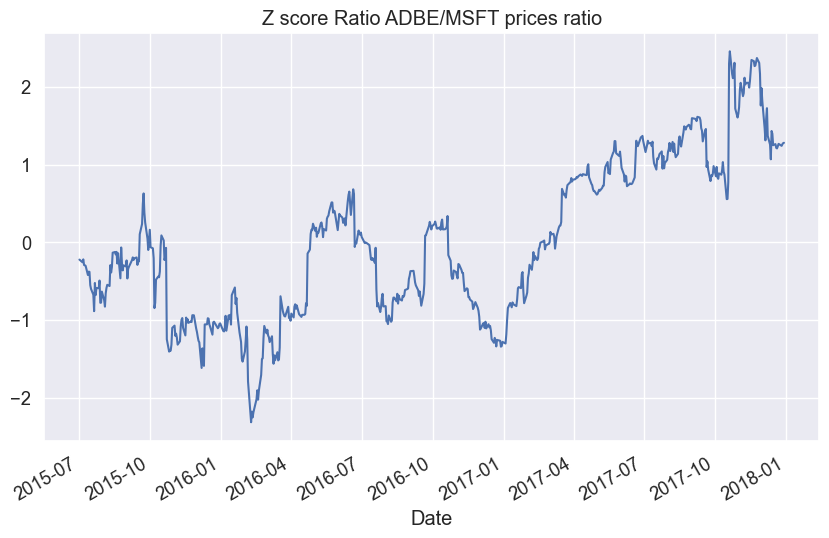

In [27]:
signals['z_score'].plot()
plt.title('Z score Ratio ADBE/MSFT prices ratio')
plt.show()

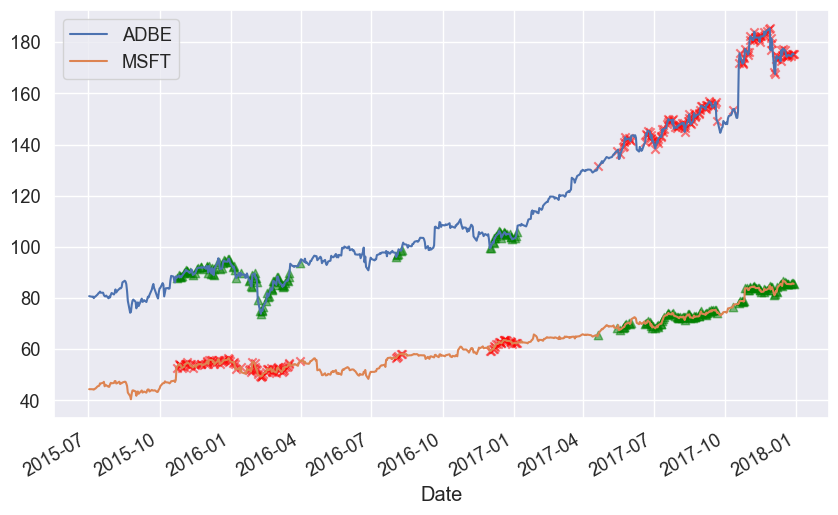

In [26]:
df = signals.loc[:,['asset_1','asset_2']]

asset_1_buy_signals = signals.loc[signals['signal_1'] == 1,'asset_1']
asset_1_sell_signals = signals.loc[signals['signal_1'] == -1,'asset_1']
asset_2_buy_signals = signals.loc[signals['signal_2'] == 1,'asset_2']
asset_2_sell_signals = signals.loc[signals['signal_2'] == -1,'asset_2']
x_1_b = asset_1_buy_signals.index
y_1_b = asset_1_buy_signals.values
x_1_s = asset_1_sell_signals.index
y_1_s = asset_1_sell_signals.values
x_2_b = asset_2_buy_signals.index
y_2_b = asset_2_buy_signals.values
x_2_s = asset_2_sell_signals.index
y_2_s = asset_2_sell_signals.values

df['asset_1'].plot(label = 'ADBE')
df['asset_2'].plot(label = 'MSFT')
plt.scatter(x_1_b,y_1_b, marker='^',color = 'green',alpha = 0.5)
plt.scatter(x_1_s,y_1_s, marker='x',color = 'red',alpha = 0.5)
plt.scatter(x_2_b,y_2_b, marker='^',color = 'green',alpha = 0.5)
plt.scatter(x_2_s,y_2_s, marker='x',color = 'red',alpha = 0.5)
plt.legend()
plt.show()

### Portfolio Profit and Loss Calculation

We will start with an initial capital of 100,000 and calculate the maximum number of shares position for each stock using the initial capital. On any given day, total profit and loss from the first stock will be total holding in that stock and cash position for that stock. Similarly, profit and loss for the second stock will be total holding in the stock and cash for that stock. You need to keep in mind that we have a market neutral position which means we go long and short simultaneously with approximately the same capital. Finally, to get the total profit and loss we have to aggregate these two. Based on the position for the stock 1 and 2, we calculate their respective daily returns. We will also add a z-score column with upper and lower threshold columns to the final portfolio dataframe for visualization purposes.

- We start with the initial capital of 100,000 and calculate the number of shares to buy for each stock.
- Next, we calculate holding in the first stock by taking the cumulative sum of its position multiplied by stock price and the total number of shares.
- We then calculate the cash position by subtracting holding from the initial cash position. The total position of stock in the portfolio is the sum of cash plus holding.
- Calculate daily returns using total stock position.
- Next, we follow the steps 1 to 4 for the second stock and sum up two asset's positions for the total portfolio value.
- Add the z-score with upper and lower thresholds for visualization.
- Visualize the portfolio performance along with z-score, upper, and lower thresholds.
- Calculate portfolio CAGR.

In [72]:
initial_capital = 100000
position_s1 = initial_capital// max(signals['asset_1'])
position_s2 = initial_capital// max(signals['asset_2'])

# since there are two assets, we calculate each asset Pnl 
# separately and in the end we aggregate them into one portfolio


portfolio = pd.DataFrame()
portfolio['asset_1'] = signals['asset_1']
portfolio['signal_1'] = signals['signal_1']
portfolio['position_1'] = signals['position_1']
portfolio['holding_1'] = signals['position_1'].cumsum()*signals['asset_1']*position_s1
portfolio['cash_1'] = initial_capital - (signals['position_1']*signals['asset_1']*position_s1).cumsum()
portfolio['total_asset_1'] = portfolio['holding_1'] + portfolio['cash_1']
portfolio['return_1'] = portfolio['total_asset_1'].pct_change()


# pnl for the 2nd asset
portfolio['asset_2'] = signals['asset_2']
portfolio['signal_2'] = signals['signal_2']
portfolio['position_2'] = signals['position_2']
portfolio['holding_2'] = signals['position_2'].cumsum()*signals['asset_2']*position_s1
portfolio['cash_2'] = initial_capital - (signals['position_1']*signals['asset_2']*position_s1).cumsum()
portfolio['total_asset_2'] = portfolio['holding_2'] + portfolio['cash_2']
portfolio['return_2'] = portfolio['total_asset_2'].pct_change()


# total pnl and z-score
portfolio['z_score'] = signals['z_score']
portfolio['total asset'] = portfolio['total_asset_1'] + portfolio['total_asset_2']
portfolio['z_up_threshold'] = signals['z_up_threshold']
portfolio['z_low_threshold'] = signals['z_low_threshold']
portfolio = portfolio.dropna()

### Summary

In [76]:
# calculate CAGR
initial_portfolio = portfolio['total asset'].iloc[0]
final_portfolio = portfolio['total asset'].iloc[-1]
delta = (portfolio.index[-1] - portfolio.index[0]).days
print('Number of days = ', delta)
YEAR_DAYS = 365
returns = (final_portfolio/initial_portfolio) ** (YEAR_DAYS/delta) - 1
print('CAGR = {:.3f}%' .format(returns * 100))


Number of days =  906
CAGR = 15.853%
